# 🏠 House Price Prediction — End-to-End Machine Learning Pipeline

**Author:** Allulu Alkheraiji

## Problem
Predict the final sale price of residential homes in Ames, Iowa, using 79 features that describe size, quality, location, and condition.

**Dataset:** [Kaggle — House Prices: Advanced Regression Techniques](https://www.kaggle.com/c/house-prices-advanced-regression-techniques)

**Evaluation metric:** RMSE on the **log** of the sale price (the official Kaggle metric), so errors on cheap and expensive houses count equally.

## Workflow
1. Setup & data loading
2. Exploratory Data Analysis (EDA)
3. Data cleaning & feature engineering
4. Preprocessing pipeline
5. Model comparison with 5-fold cross-validation
6. Hyperparameter tuning
7. Hold-out evaluation & error analysis
8. Feature importance
9. Final model & Kaggle submission
10. Conclusions

## 1) Setup

In [1]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

from sklearn.model_selection import train_test_split, KFold, cross_val_score, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
pd.set_option('display.max_columns', 30)
print('Libraries loaded ✅')

Libraries loaded ✅


## 2) Data Loading
Download `train.csv` and `test.csv` from the Kaggle competition page.
In Google Colab, run the cell below — if the files are not found, an upload button will appear.

In [2]:
try:
    from google.colab import files
    if not (Path('train.csv').exists() and Path('test.csv').exists()):
        files.upload()   # choose train.csv and test.csv
except ImportError:
    pass  # running locally

train_df = pd.read_csv('train.csv')
test_df  = pd.read_csv('test.csv')
TARGET = 'SalePrice'

print('Train shape:', train_df.shape)
print('Test shape :', test_df.shape)
train_df.head()

Train shape: (1460, 81)
Test shape : (1459, 80)


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,...,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,...,0,61,0,0,0,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,FR2,Gtl,Veenker,Feedr,Norm,...,298,0,0,0,0,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,...,0,42,0,0,0,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,Corner,Gtl,Crawfor,Norm,Norm,...,0,35,272,0,0,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,FR2,Gtl,NoRidge,Norm,Norm,...,192,84,0,0,0,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


## 3) Exploratory Data Analysis (EDA)
### 3.1 Feature types & target summary

In [3]:
num_features = train_df.drop(columns=['Id', TARGET]).select_dtypes(include='number').columns
cat_features = train_df.drop(columns=['Id', TARGET]).select_dtypes(exclude='number').columns
print(f'Numeric features: {len(num_features)} | Categorical features: {len(cat_features)}')
train_df[TARGET].describe().round(0)

Numeric features: 36 | Categorical features: 43


count      1460.0
mean     180921.0
std       79443.0
min       34900.0
25%      129975.0
50%      163000.0
75%      214000.0
max      755000.0
Name: SalePrice, dtype: float64

### 3.2 Target distribution — raw vs. log

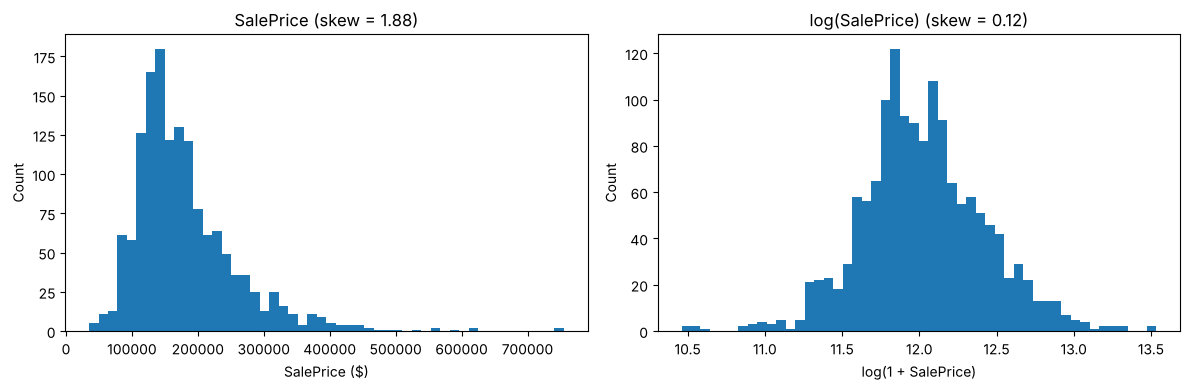

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(train_df[TARGET], bins=50)
axes[0].set_title(f'SalePrice (skew = {train_df[TARGET].skew():.2f})')
axes[0].set_xlabel('SalePrice ($)')
axes[1].hist(np.log1p(train_df[TARGET]), bins=50)
axes[1].set_title(f'log(SalePrice) (skew = {np.log1p(train_df[TARGET]).skew():.2f})')
axes[1].set_xlabel('log(1 + SalePrice)')
for ax in axes: ax.set_ylabel('Count')
plt.tight_layout(); plt.show()

**Insight:** Prices are right-skewed (a long tail of expensive houses). A log transform makes the target close to normal, which helps linear models and matches the Kaggle metric.

### 3.3 Missing values

In [5]:
missing = train_df.isna().sum()
missing = missing[missing > 0].sort_values(ascending=False)
missing_df = pd.DataFrame({'Missing': missing, 'Percent': (missing / len(train_df) * 100).round(1)})
missing_df

,Missing,Percent
PoolQC,1453,99.5
MiscFeature,1406,96.3
Alley,1369,93.8
Fence,1179,80.8
MasVnrType,872,59.7
FireplaceQu,690,47.3
LotFrontage,259,17.7
GarageType,81,5.5
GarageYrBlt,81,5.5
GarageFinish,81,5.5


**Insight:** Most missing values are not errors. For features like `PoolQC`, `Alley`, `Fence`, `FireplaceQu`, garage and basement columns, a missing value means the house **does not have** that feature.
- Categorical gaps → filled with the label `"None"`
- Numeric gaps (e.g. `LotFrontage`) → filled with the median

### 3.4 Features most correlated with price

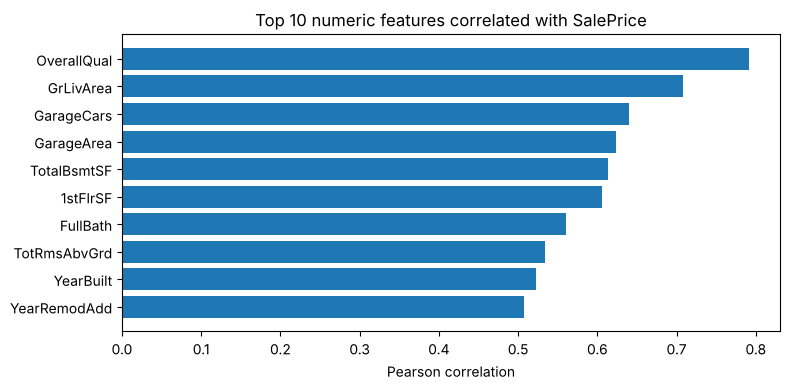

OverallQual     0.791
GrLivArea       0.709
GarageCars      0.640
GarageArea      0.623
TotalBsmtSF     0.614
1stFlrSF        0.606
FullBath        0.561
TotRmsAbvGrd    0.534
YearBuilt       0.523
YearRemodAdd    0.507
Name: SalePrice, dtype: float64

In [6]:
corr = train_df[list(num_features) + [TARGET]].corr()[TARGET].drop(TARGET).sort_values(ascending=False)
top_corr = corr.head(10)

plt.figure(figsize=(8, 4))
plt.barh(top_corr.index[::-1], top_corr.values[::-1])
plt.title('Top 10 numeric features correlated with SalePrice')
plt.xlabel('Pearson correlation')
plt.tight_layout(); plt.show()
top_corr.round(3)

### 3.5 Outliers

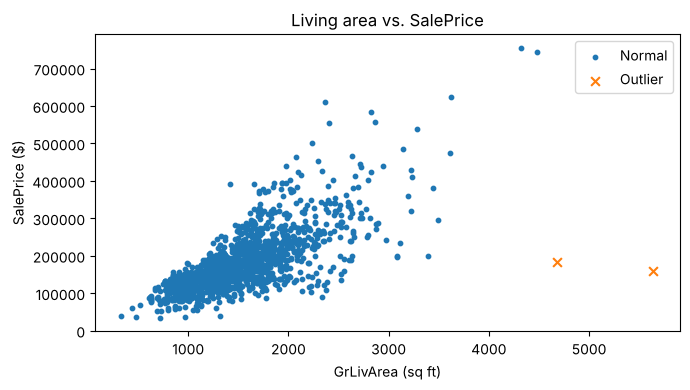

Outliers found: 2


In [7]:
outlier_mask = (train_df['GrLivArea'] > 4000) & (train_df[TARGET] < 300000)

plt.figure(figsize=(7, 4))
plt.scatter(train_df.loc[~outlier_mask, 'GrLivArea'], train_df.loc[~outlier_mask, TARGET], s=10, label='Normal')
plt.scatter(train_df.loc[outlier_mask, 'GrLivArea'], train_df.loc[outlier_mask, TARGET], s=40, marker='x', label='Outlier')
plt.title('Living area vs. SalePrice')
plt.xlabel('GrLivArea (sq ft)'); plt.ylabel('SalePrice ($)')
plt.legend(); plt.tight_layout(); plt.show()
print('Outliers found:', outlier_mask.sum())

**Insight:** Two very large houses sold at unusually low prices. They break the clear size–price trend and can mislead the model, so they are removed from training.

## 4) Data Cleaning & Feature Engineering

In [8]:
train_clean = train_df[~outlier_mask].reset_index(drop=True)

def engineer_features(df):
    df = df.copy()
    # MSSubClass is a building-type code, not a quantity
    df['MSSubClass'] = df['MSSubClass'].astype(str)
    # New features
    df['TotalSF']    = df['TotalBsmtSF'].fillna(0) + df['1stFlrSF'] + df['2ndFlrSF']
    df['TotalBath']  = (df['FullBath'] + 0.5 * df['HalfBath']
                        + df['BsmtFullBath'].fillna(0) + 0.5 * df['BsmtHalfBath'].fillna(0))
    df['HouseAge']   = df['YrSold'] - df['YearBuilt']
    df['RemodAge']   = df['YrSold'] - df['YearRemodAdd']
    df['TotalPorch'] = (df['OpenPorchSF'] + df['EnclosedPorch'] + df['3SsnPorch']
                        + df['ScreenPorch'] + df['WoodDeckSF'])
    return df.drop(columns=['Id'])

X = engineer_features(train_clean.drop(columns=[TARGET]))
y = np.log1p(train_clean[TARGET])          # model works on log price
X_test = engineer_features(test_df)

print('Rows after removing outliers:', len(X))
print('Features after engineering :', X.shape[1])

Rows after removing outliers: 1458
Features after engineering : 84


**New features**
- `TotalSF` — total indoor area (basement + floors)
- `TotalBath` — all bathrooms, half baths counted as 0.5
- `HouseAge` / `RemodAge` — age at sale and years since remodeling
- `TotalPorch` — all outdoor living areas combined

## 5) Preprocessing Pipeline

In [9]:
num_cols = X.select_dtypes(include='number').columns.tolist()
cat_cols = X.select_dtypes(exclude='number').columns.tolist()

numeric_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler',  StandardScaler()),
])
categorical_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='constant', fill_value='None')),
    ('onehot',  OneHotEncoder(handle_unknown='ignore')),
])
preprocessor = ColumnTransformer([
    ('num', numeric_pipe, num_cols),
    ('cat', categorical_pipe, cat_cols),
])
print(f'Numeric: {len(num_cols)} | Categorical: {len(cat_cols)} — preprocessor ready ✅')

Numeric: 40 | Categorical: 44 — preprocessor ready ✅


All steps live inside a `Pipeline`, so imputation and scaling are learned **only from training folds** — no information leaks from validation data.

## 6) Model Comparison — 5-Fold Cross-Validation

In [10]:
kf = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

models = {
    'Linear Regression': LinearRegression(),
    'Ridge':             Ridge(alpha=10),
    'Lasso':             Lasso(alpha=0.0005, max_iter=50000),
    'ElasticNet':        ElasticNet(alpha=0.0005, l1_ratio=0.5, max_iter=50000),
    'Random Forest':     RandomForestRegressor(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1),
    'Gradient Boosting': GradientBoostingRegressor(random_state=RANDOM_STATE),
}

results = []
for name, model in models.items():
    pipe = Pipeline([('preprocess', preprocessor), ('model', model)])
    scores = -cross_val_score(pipe, X, y, cv=kf, scoring='neg_root_mean_squared_error', n_jobs=-1)
    results.append({'Model': name, 'CV RMSE (log)': scores.mean(), 'Std': scores.std()})

cv_df = pd.DataFrame(results).sort_values('CV RMSE (log)').reset_index(drop=True)
cv_df.round(4)

,Model,CV RMSE (log),Std
0,Lasso,0.1116,0.0066
1,ElasticNet,0.1130,0.0065
2,Ridge,0.1142,0.0084
3,Gradient Boosting,0.1251,0.0069
4,Linear Regression,0.1346,0.0152
5,Random Forest,0.1359,0.0070


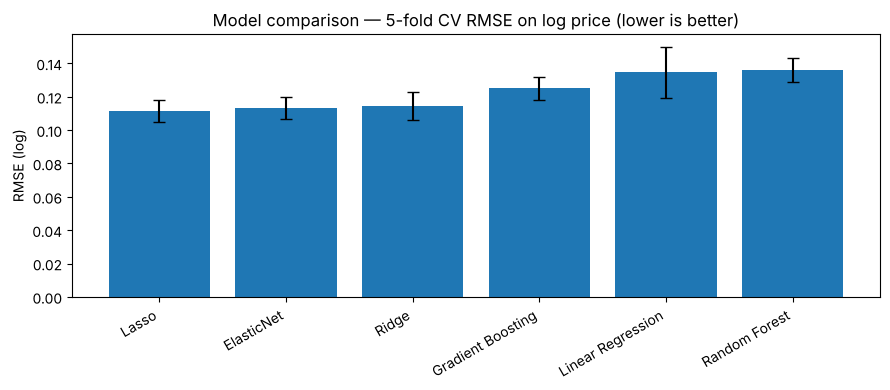

In [11]:
plt.figure(figsize=(9, 4))
plt.bar(cv_df['Model'], cv_df['CV RMSE (log)'], yerr=cv_df['Std'], capsize=4)
plt.title('Model comparison — 5-fold CV RMSE on log price (lower is better)')
plt.ylabel('RMSE (log)')
plt.xticks(rotation=30, ha='right')
plt.tight_layout(); plt.show()

## 7) Hyperparameter Tuning

### 7.1 Gradient Boosting — randomized search

In [12]:
gbr_pipe = Pipeline([('preprocess', preprocessor),
                     ('model', GradientBoostingRegressor(random_state=RANDOM_STATE))])

param_dist = {
    'model__n_estimators':     [500, 1000, 1500],
    'model__learning_rate':    [0.02, 0.05, 0.1],
    'model__max_depth':        [2, 3, 4],
    'model__subsample':        [0.7, 0.85, 1.0],
    'model__min_samples_leaf': [5, 10, 15],
    'model__max_features':     ['sqrt', 0.3],
}
gbr_search = RandomizedSearchCV(gbr_pipe, param_dist, n_iter=15, cv=kf,
                                scoring='neg_root_mean_squared_error',
                                random_state=RANDOM_STATE, n_jobs=-1)
gbr_search.fit(X, y)
print('Best CV RMSE (log):', round(-gbr_search.best_score_, 4))
print('Best params:', {k.replace('model__', ''): v for k, v in gbr_search.best_params_.items()})

Best CV RMSE (log): 0.1132
Best params: {'subsample': 0.85, 'n_estimators': 1000, 'min_samples_leaf': 5, 'max_features': 0.3, 'max_depth': 2, 'learning_rate': 0.05}


### 7.2 Lasso — tuning the regularization strength

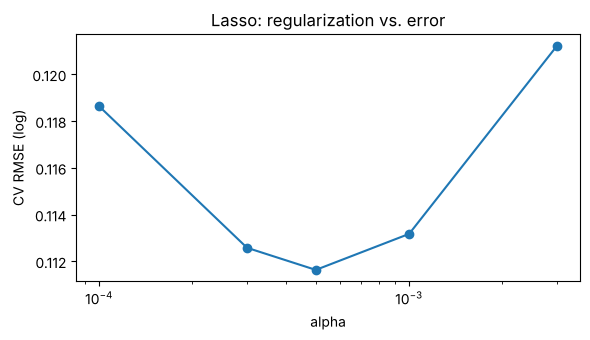

Best alpha: 0.0005 | CV RMSE (log): 0.1116


In [13]:
lasso_pipe = Pipeline([('preprocess', preprocessor), ('model', Lasso(max_iter=50000))])
alphas = [0.0001, 0.0003, 0.0005, 0.001, 0.003]
lasso_scores = []
for a in alphas:
    lasso_pipe.set_params(model__alpha=a)
    s = -cross_val_score(lasso_pipe, X, y, cv=kf, scoring='neg_root_mean_squared_error', n_jobs=-1)
    lasso_scores.append(s.mean())

best_alpha = alphas[int(np.argmin(lasso_scores))]
plt.figure(figsize=(6, 3.5))
plt.plot(alphas, lasso_scores, marker='o')
plt.xscale('log'); plt.xlabel('alpha'); plt.ylabel('CV RMSE (log)')
plt.title('Lasso: regularization vs. error')
plt.tight_layout(); plt.show()
print('Best alpha:', best_alpha, '| CV RMSE (log):', round(min(lasso_scores), 4))

### 7.3 Simple ensemble — average of tuned Gradient Boosting and Lasso

In [14]:
best_gbr   = gbr_search.best_estimator_
best_lasso = Pipeline([('preprocess', preprocessor), ('model', Lasso(alpha=best_alpha, max_iter=50000))])

blend_scores = []
for tr, va in kf.split(X):
    p1 = best_gbr.fit(X.iloc[tr], y.iloc[tr]).predict(X.iloc[va])
    p2 = best_lasso.fit(X.iloc[tr], y.iloc[tr]).predict(X.iloc[va])
    blend_scores.append(mean_squared_error(y.iloc[va], (p1 + p2) / 2) ** 0.5)

tuned_df = pd.DataFrame({
    'Model': ['Tuned Gradient Boosting', 'Tuned Lasso', 'Blend (GBR + Lasso)'],
    'CV RMSE (log)': [-gbr_search.best_score_, min(lasso_scores), np.mean(blend_scores)],
}).sort_values('CV RMSE (log)').reset_index(drop=True)
tuned_df.round(4)

,Model,CV RMSE (log)
0,Blend (GBR + Lasso),0.1083
1,Tuned Lasso,0.1116
2,Tuned Gradient Boosting,0.1132


## 8) Hold-out Evaluation & Error Analysis
The models are trained on 80% of the data and tested on the remaining 20% they have **never seen**. Metrics are converted back to dollars so they are easy to interpret.

In [15]:
X_train, X_valid, y_train, y_valid = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)

best_gbr.fit(X_train, y_train)
best_lasso.fit(X_train, y_train)
pred_log = (best_gbr.predict(X_valid) + best_lasso.predict(X_valid)) / 2

actual = np.expm1(y_valid)
pred   = np.expm1(pred_log)

print(f'RMSE (log) : {mean_squared_error(y_valid, pred_log) ** 0.5:.4f}')
print(f'RMSE ($)   : {mean_squared_error(actual, pred) ** 0.5:,.0f}')
print(f'MAE  ($)   : {mean_absolute_error(actual, pred):,.0f}')
print(f'MAPE       : {np.mean(np.abs(actual - pred) / actual) * 100:.1f}%')
print(f'R²         : {r2_score(actual, pred):.3f}')

RMSE (log) : 0.1121
RMSE ($)   : 18,395
MAE  ($)   : 13,291
MAPE       : 8.1%
R²         : 0.939


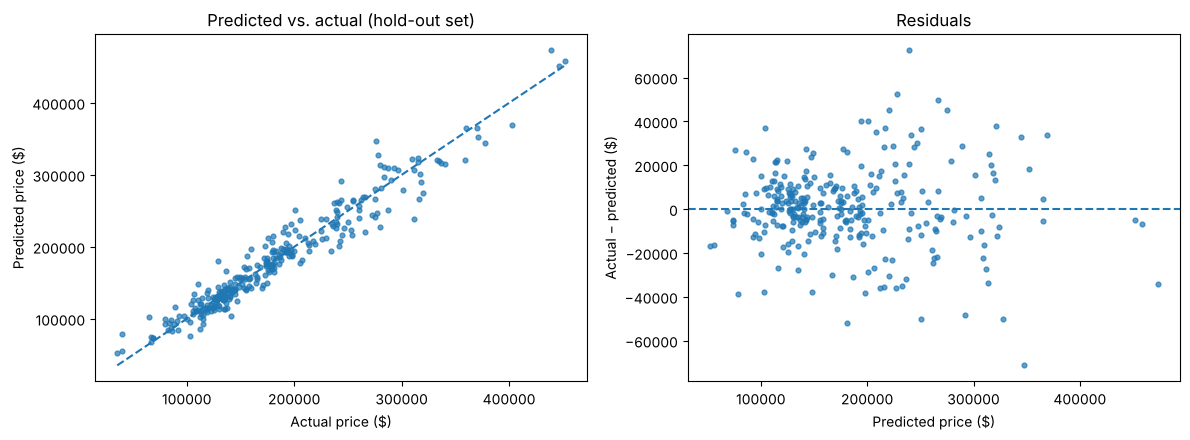

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
lims = [actual.min(), actual.max()]
axes[0].scatter(actual, pred, s=12, alpha=0.7)
axes[0].plot(lims, lims, linestyle='--')
axes[0].set_title('Predicted vs. actual (hold-out set)')
axes[0].set_xlabel('Actual price ($)'); axes[0].set_ylabel('Predicted price ($)')

residuals = actual - pred
axes[1].scatter(pred, residuals, s=12, alpha=0.7)
axes[1].axhline(0, linestyle='--')
axes[1].set_title('Residuals')
axes[1].set_xlabel('Predicted price ($)'); axes[1].set_ylabel('Actual − predicted ($)')
plt.tight_layout(); plt.show()

In [17]:
errors = X_valid[['OverallQual', 'GrLivArea', 'Neighborhood', 'SaleCondition']].copy()
errors['Actual'] = actual.round(0)
errors['Predicted'] = pred.round(0)
errors['Abs % Error'] = (np.abs(actual - pred) / actual * 100).round(1)
errors.sort_values('Abs % Error', ascending=False).head(8)

,OverallQual,GrLivArea,Neighborhood,SaleCondition,Actual,Predicted,Abs % Error
30,4,1317,IDOTRR,Normal,40000.0,78548.0,96.4
1430,4,968,OldTown,Normal,64500.0,102541.0,59.0
915,2,480,IDOTRR,Abnorml,35311.0,52179.0,47.8
532,1,334,BrkSide,Normal,39300.0,55846.0,42.1
665,6,2380,NAmes,Abnorml,129000.0,180893.0,40.2
727,5,1776,NAmes,Abnorml,110000.0,147921.0,34.5
479,4,1131,OldTown,Alloca,89471.0,116419.0,30.1
710,4,1178,IDOTRR,Abnorml,102776.0,75851.0,26.2


## 9) Feature Importance (Tuned Gradient Boosting)

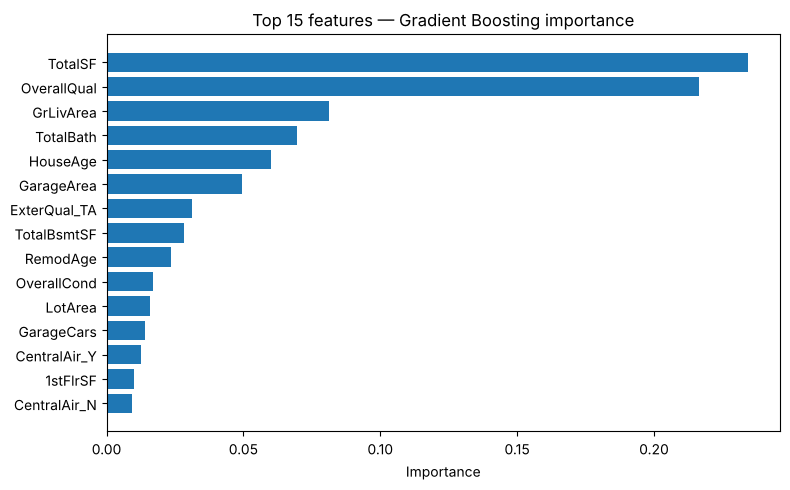

TotalSF         0.2343
OverallQual     0.2163
GrLivArea       0.0812
TotalBath       0.0697
HouseAge        0.0600
GarageArea      0.0494
ExterQual_TA    0.0311
TotalBsmtSF     0.0284
RemodAge        0.0237
OverallCond     0.0171
LotArea         0.0160
GarageCars      0.0139
CentralAir_Y    0.0126
1stFlrSF        0.0099
CentralAir_N    0.0093
dtype: float64

In [18]:
best_gbr.fit(X, y)
feature_names = best_gbr.named_steps['preprocess'].get_feature_names_out()
feature_names = [f.split('__', 1)[1] for f in feature_names]
importances = pd.Series(best_gbr.named_steps['model'].feature_importances_, index=feature_names)
top15 = importances.sort_values(ascending=False).head(15)

plt.figure(figsize=(8, 5))
plt.barh(top15.index[::-1], top15.values[::-1])
plt.title('Top 15 features — Gradient Boosting importance')
plt.xlabel('Importance')
plt.tight_layout(); plt.show()
top15.round(4)

## 10) Final Model & Kaggle Submission
Both tuned models are retrained on **all** cleaned training data, and their predictions are averaged.

In [19]:
best_gbr.fit(X, y)
best_lasso.fit(X, y)
test_pred_log = (best_gbr.predict(X_test) + best_lasso.predict(X_test)) / 2

submission = pd.DataFrame({'Id': test_df['Id'], 'SalePrice': np.expm1(test_pred_log)})
submission.to_csv('submission.csv', index=False)
print('submission.csv saved ✅', submission.shape)
submission.head()

submission.csv saved ✅ (1459, 2)


,Id,SalePrice
0,1461,123603.354153
1,1462,157772.758734
2,1463,182029.944351
3,1464,199217.829380
4,1465,190507.299109


## 11) Conclusions

### Results
| Stage | Best model | CV RMSE (log) |
|---|---|---|
| Baseline comparison | Lasso | 0.1116 |
| After tuning | Tuned Gradient Boosting | 0.1132 |
| Final | **Blend (Gradient Boosting + Lasso)** | **0.1083** |

On the unseen hold-out set, the final blend reached **R² ≈ 0.94** with an average error (MAE) of about **$13K**, roughly **8%** of the house price.

### Key insights
- **Size and quality drive price.** `TotalSF` (an engineered feature) and `OverallQual` are by far the most important features.
- **Feature engineering paid off.** Three of the top five features (`TotalSF`, `TotalBath`, `HouseAge`) were created in this notebook.
- **Log-transforming the target and scaling helped linear models a lot.** With these steps, regularized linear models (Lasso, Ridge) beat tree models out of the box.
- **Blending works.** Lasso captures linear trends while Gradient Boosting captures non-linear interactions, so averaging them reduced the error further.

### Limitations
- The largest errors are on **cheap houses** in older neighborhoods (e.g. `IDOTRR`, `OldTown`) and on **abnormal sales** (foreclosures, family sales), where the price depends on circumstances not fully captured in the data.
- The dataset is small (~1,460 houses) and from one city, so the model may not generalize to other markets.

### Next steps
- Try XGBoost / LightGBM / CatBoost and a stacking ensemble.
- Treat skewed numeric features with log or Box-Cox transforms.
- Add neighborhood-level features (e.g. median price per neighborhood, computed inside CV to avoid leakage).